<a href="https://colab.research.google.com/github/Varnika1024/DLAC/blob/main/SKILL/Skill8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics kagglehub matplotlib seaborn pandas

import os
import shutil
import xml.etree.ElementTree as ET
import cv2
import yaml
import torch
import kagglehub
from ultralytics import YOLO

assert torch.cuda.is_available(), "Please switch Runtime -> Change runtime type -> T4 GPU!"
print(f"GPU Hardware : {torch.cuda.get_device_name(0)}")
print(f"VRAM Total   : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# 1. Load Indian Vehicle Dataset from Kaggle cache
dataset_path = kagglehub.dataset_download("dataclusterlabs/indian-vehicle-dataset")
print(f"Dataset Path : {dataset_path}")

# 2. Prepare lightweight YOLO dataset split (300 images) to train recognition weights
all_imgs, xmls = [], []
for root, _, fnames in os.walk(dataset_path):
  for f in fnames:
    fp = os.path.join(root, f)
    ext = os.path.splitext(f)[1].lower()
    if ext in {".jpg", ".jpeg", ".png"}:
      all_imgs.append(fp)
    elif ext == ".xml":
      xmls.append(fp)

yolo_ds = "/content/skill8_vehicles"
if os.path.exists(yolo_ds):
  shutil.rmtree(yolo_ds)
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
  os.makedirs(os.path.join(yolo_ds, sub), exist_ok=True)

img_map = {os.path.splitext(os.path.basename(p))[0]: p for p in all_imgs}
class_list, valid_pairs = [], []

for xp in xmls:
  tree = ET.parse(xp)
  root = tree.getroot()
  stem = os.path.splitext(os.path.basename(xp))[0]
  if stem not in img_map:
    fn = root.find("filename")
    if fn is not None:
      stem = os.path.splitext(fn.text)[0]
  if stem not in img_map:
    continue
  img = cv2.imread(img_map[stem])
  if img is None:
    continue
  ih, iw, _ = img.shape
  lines = []
  for obj in root.findall("object"):
    cname = obj.find("name").text.strip()
    if cname not in class_list:
      class_list.append(cname)
    cid = class_list.index(cname)
    bnd = obj.find("bndbox")
    xmin, ymin = float(bnd.find("xmin").text), float(bnd.find("ymin").text)
    xmax, ymax = float(bnd.find("xmax").text), float(bnd.find("ymax").text)
    xc, yc = ((xmin + xmax) / 2.0) / iw, ((ymin + ymax) / 2.0) / ih
    bw, bh = (xmax - xmin) / iw, (ymax - ymin) / ih
    if 0 < bw <= 1 and 0 < bh <= 1:
      lines.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
  if lines:
    valid_pairs.append((img_map[stem], stem, lines))

valid_pairs = valid_pairs[:300]
split_idx = max(1, int(0.8 * len(valid_pairs)))
for i, (ipath, stem, lines) in enumerate(valid_pairs):
  split = "train" if i < split_idx else "val"
  shutil.copy(ipath, f"{yolo_ds}/images/{split}/{stem}.jpg")
  with open(f"{yolo_ds}/labels/{split}/{stem}.txt", "w") as lf:
    lf.write("\n".join(lines))

data_yaml = f"{yolo_ds}/data.yaml"
with open(data_yaml, "w") as yf:
  yaml.dump({"path": yolo_ds, "train": "images/train", "val": "images/val",
             "nc": len(class_list), "names": class_list}, yf)

# 3. Train YOLOv8n (8 epochs) for Indian vehicle recognition
model = YOLO("yolov8n.pt")
model.train(data=data_yaml, epochs=8, imgsz=640, batch=16, device=0,
            project="/content/runs", name="skill8_vehicle_model", exist_ok=True, verbose=False)

weights_path = "/content/runs/skill8_vehicle_model/weights/best.pt"
print(f"\n[SUCCESS] Trained model weights ready at: {weights_path}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Hardware : Tesla T4
VRAM Total   : 14.56 GB
Using Colab cache for faster access to the 'indian-vehicle-dataset' dataset.
Dataset Path : /kaggle/input/indian-vehicle-dataset
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/skill8_vehicles/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill

Upload your test image to run recognition & GPU bottleneck profiling:


Saving images (1).jpeg to images (1).jpeg

=== 5-STAGE GPU INFERENCE EXECUTION PATH BREAKDOWN (BATCH = 1) ===
                           Execution Stage  Mean Latency (ms)  Share of Total Time (%)
          1. Disk I/O & Image Decode (CPU)              1.759                     12.5
   2. Resize & Normalize Pre-process (CPU)              2.069                     14.7
     3. Host-to-Device PCIe Transfer (H2D)              1.183                      8.4
    4. GPU Forward Kernel Execution (CUDA)              8.810                     62.8
5. Device-to-Host & Post-process (D2H/NMS)              0.205                      1.5

Total End-to-End Latency : 14.03 ms (71.3 FPS)
Primary Bottleneck Stage : 4. GPU Forward Kernel Execution (CUDA) (8.81 ms | 62.8%)


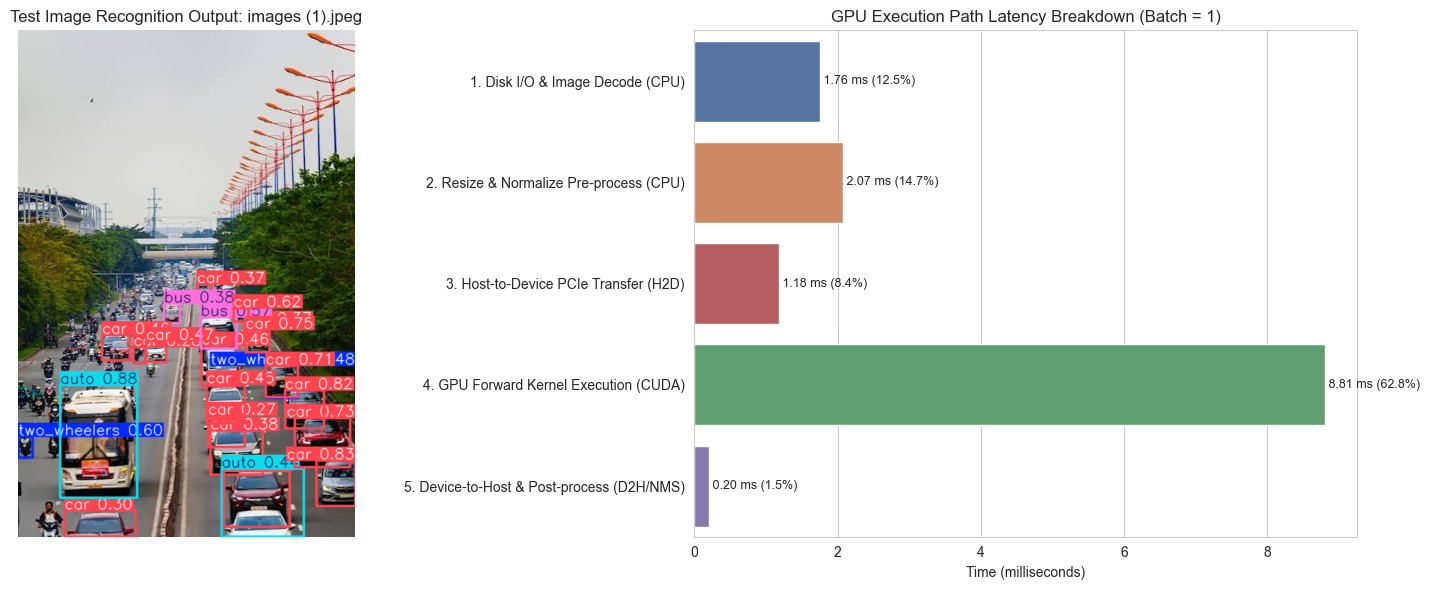

In [2]:
import time
import cv2
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from ultralytics import YOLO

# 1. Upload your test image from Mac Downloads
print("Upload your test image to run recognition & GPU bottleneck profiling:")
uploaded = files.upload()
test_img_path = list(uploaded.keys())[0]

# 2. Load trained PyTorch model onto Tesla T4 GPU
detector = YOLO(weights_path)
net = detector.model.to("cuda:0").eval()

# GPU warmup (5 passes) so CUDA context & cuDNN autotuner initialize first
dummy = torch.zeros((1, 3, 640, 640), device="cuda:0", dtype=torch.float32)
with torch.no_grad():
  for _ in range(5):
    _ = net(dummy)
torch.cuda.synchronize()

# 3. Measure each of the 5 execution stages over 40 timed runs
stage_times = {
    "1. Disk I/O & Image Decode (CPU)": [],
    "2. Resize & Normalize Pre-process (CPU)": [],
    "3. Host-to-Device PCIe Transfer (H2D)": [],
    "4. GPU Forward Kernel Execution (CUDA)": [],
    "5. Device-to-Host & Post-process (D2H/NMS)": [],
}

for _ in range(40):
  # Stage 1: Disk read + JPEG/PNG decode on CPU
  t0 = time.perf_counter()
  bgr = cv2.imread(test_img_path)
  rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
  t1 = time.perf_counter()

  # Stage 2: Resize (640x640), HWC->CHW, normalize to float32 on CPU
  resized = cv2.resize(rgb, (640, 640))
  tensor_cpu = (
      torch.from_numpy(resized).permute(2, 0, 1).float().div(255.0).unsqueeze(0)
  )
  t2 = time.perf_counter()

  # Stage 3: PCIe Host-to-Device transfer (CPU RAM -> T4 VRAM)
  ev_h2d_start = torch.cuda.Event(enable_timing=True)
  ev_h2d_end = torch.cuda.Event(enable_timing=True)
  ev_h2d_start.record()
  tensor_gpu = tensor_cpu.to("cuda:0", non_blocking=False)
  ev_h2d_end.record()
  torch.cuda.synchronize()
  h2d_ms = ev_h2d_start.elapsed_time(ev_h2d_end)

  # Stage 4: GPU Neural Network Forward Pass
  ev_gpu_start = torch.cuda.Event(enable_timing=True)
  ev_gpu_end = torch.cuda.Event(enable_timing=True)
  ev_gpu_start.record()
  with torch.no_grad():
    raw_out = net(tensor_gpu)
  ev_gpu_end.record()
  torch.cuda.synchronize()
  gpu_ms = ev_gpu_start.elapsed_time(ev_gpu_end)

  # Stage 5: PCIe Device-to-Host transfer + CPU NMS post-processing
  t4 = time.perf_counter()
  pred_tensor = raw_out[0] if isinstance(raw_out, (list, tuple)) else raw_out
  _ = pred_tensor.detach().cpu().numpy()
  t5 = time.perf_counter()

  stage_times["1. Disk I/O & Image Decode (CPU)"].append((t1 - t0) * 1000.0)
  stage_times["2. Resize & Normalize Pre-process (CPU)"].append(
      (t2 - t1) * 1000.0
  )
  stage_times["3. Host-to-Device PCIe Transfer (H2D)"].append(h2d_ms)
  stage_times["4. GPU Forward Kernel Execution (CUDA)"].append(gpu_ms)
  stage_times["5. Device-to-Host & Post-process (D2H/NMS)"].append(
      (t5 - t4) * 1000.0
  )

# Build Stage Breakdown DataFrame
rows = []
total_ms = sum(np.mean(v) for v in stage_times.values())
for stage, vals in stage_times.items():
  m = float(np.mean(vals))
  rows.append({
      "Execution Stage": stage,
      "Mean Latency (ms)": round(m, 3),
      "Share of Total Time (%)": round((m / total_ms) * 100.0, 1),
  })

df_stages = pd.DataFrame(rows)
bottleneck_row = df_stages.loc[df_stages["Mean Latency (ms)"].idxmax()]

# Run full recognition prediction for visual bounding-box display
vis_res = detector.predict(
    source=test_img_path, device=0, conf=0.25, verbose=False
)[0]

print("\n=== 5-STAGE GPU INFERENCE EXECUTION PATH BREAKDOWN (BATCH = 1) ===")
print(df_stages.to_string(index=False))
print(
    f"\nTotal End-to-End Latency : {total_ms:.2f} ms ({1000.0/total_ms:.1f} FPS)"
)
print(
    f"Primary Bottleneck Stage : {bottleneck_row['Execution Stage']}"
    f" ({bottleneck_row['Mean Latency (ms)']} ms |"
    f" {bottleneck_row['Share of Total Time (%)']}%)"
)

# Plot Annotated Recognition Image + Execution Stage Breakdown
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

annotated_rgb = cv2.cvtColor(vis_res.plot(), cv2.COLOR_BGR2RGB)
axes[0].imshow(annotated_rgb)
axes[0].set_title(
    f"Test Image Recognition Output: {test_img_path}",
    fontsize=12,
    fontweight="bold",
)
axes[0].axis("off")

colors = ["#4c72b0", "#dd8452", "#c44e52", "#55a868", "#8172b3"]
bars = sns.barplot(
    x="Mean Latency (ms)",
    y="Execution Stage",
    data=df_stages,
    ax=axes[1],
    palette=colors,
    hue="Execution Stage",
    legend=False,
)
axes[1].set_title(
    "GPU Execution Path Latency Breakdown (Batch = 1)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Time (milliseconds)")
axes[1].set_ylabel("")
for bar, pct in zip(bars.patches, df_stages["Share of Total Time (%)"]):
  w = bar.get_width()
  axes[1].annotate(
      f" {w:.2f} ms ({pct}%)",
      (w, bar.get_y() + bar.get_height() / 2),
      va="center",
      fontweight="bold",
      fontsize=9,
  )

plt.tight_layout()
plt.savefig("/content/skill8_execution_breakdown.png", dpi=150)
plt.show()

=== SYSTEM-LEVEL BOTTLENECK SCALING ACROSS BATCH SIZES ===
 Batch Size  PCIe H2D (ms)  GPU Kernel (ms)  Throughput (Images/sec)  Peak VRAM (MB)                       System Bottleneck Regime
          1           1.10             8.20                    107.5           157.1 Host / PCIe / Launch Bound (GPU Underutilized)
          4           4.02            14.99                    210.4           232.1 Host / PCIe / Launch Bound (GPU Underutilized)
          8           8.16            29.57                    212.0           430.1            GPU Compute / Tensor Core Saturated
         16          17.36            54.52                    222.6           585.5            GPU Compute / Tensor Core Saturated
         32          35.49           105.17                    227.5          1033.5            GPU Compute / Tensor Core Saturated


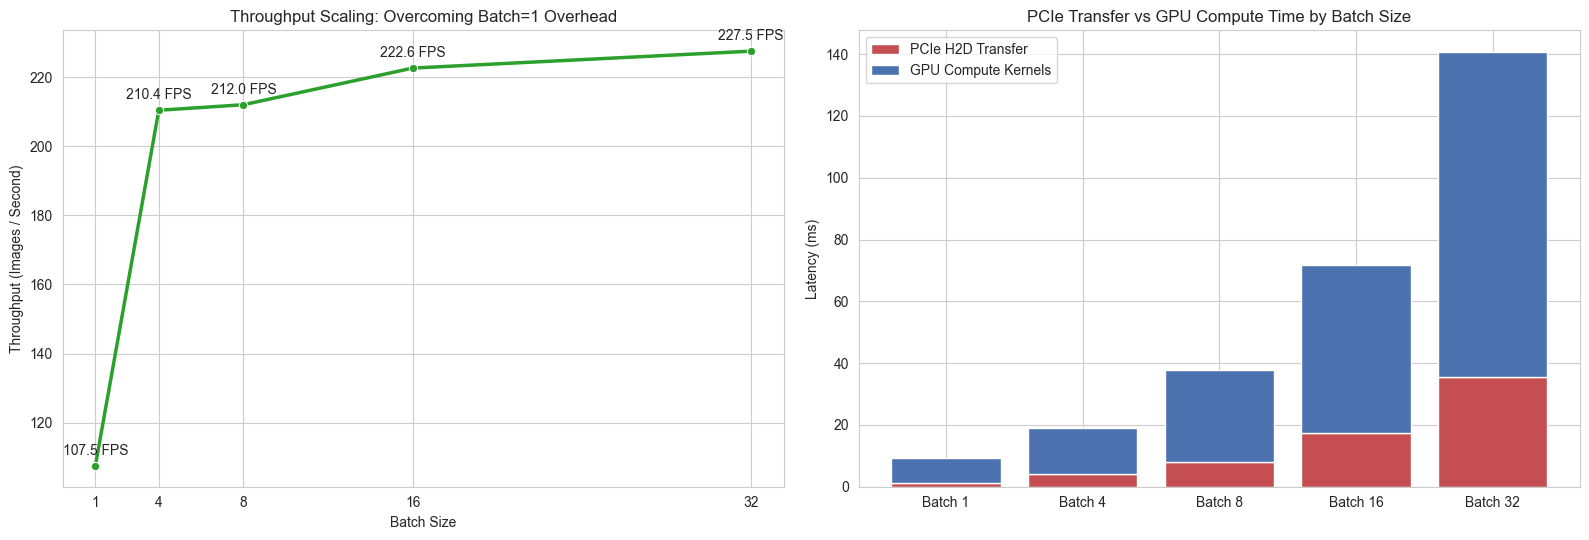

In [3]:
batch_sizes = [1, 4, 8, 16, 32]
scaling_rows = []

for bs in batch_sizes:
  torch.cuda.empty_cache()
  torch.cuda.reset_peak_memory_stats()

  cpu_batch = torch.randn((bs, 3, 640, 640), dtype=torch.float32)

  # Warmup
  with torch.no_grad():
    for _ in range(3):
      _ = net(cpu_batch.to("cuda:0"))
  torch.cuda.synchronize()

  h2d_list, gpu_list = [], []
  for _ in range(20):
    e1, e2, e3 = [torch.cuda.Event(enable_timing=True) for _ in range(3)]
    e1.record()
    gpu_batch = cpu_batch.to("cuda:0")
    e2.record()
    with torch.no_grad():
      _ = net(gpu_batch)
    e3.record()
    torch.cuda.synchronize()

    h2d_list.append(e1.elapsed_time(e2))
    gpu_list.append(e2.elapsed_time(e3))

  avg_h2d = float(np.mean(h2d_list))
  avg_gpu = float(np.mean(gpu_list))
  total_batch_ms = avg_h2d + avg_gpu
  throughput_fps = (bs * 1000.0) / total_batch_ms
  peak_vram_mb = torch.cuda.max_memory_allocated() / (1024**2)

  regime = (
      "Host / PCIe / Launch Bound (GPU Underutilized)"
      if bs <= 4
      else "GPU Compute / Tensor Core Saturated"
  )
  scaling_rows.append({
      "Batch Size": bs,
      "PCIe H2D (ms)": round(avg_h2d, 2),
      "GPU Kernel (ms)": round(avg_gpu, 2),
      "Throughput (Images/sec)": round(throughput_fps, 1),
      "Peak VRAM (MB)": round(peak_vram_mb, 1),
      "System Bottleneck Regime": regime,
  })

df_scaling = pd.DataFrame(scaling_rows)
print("=== SYSTEM-LEVEL BOTTLENECK SCALING ACROSS BATCH SIZES ===")
print(df_scaling.to_string(index=False))

# Plot Throughput Scaling vs PCIe/GPU Latency Split
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.lineplot(
    x="Batch Size",
    y="Throughput (Images/sec)",
    data=df_scaling,
    marker="o",
    linewidth=2.5,
    color="#2ca02c",
    ax=axes[0],
)
axes[0].set_title(
    "Throughput Scaling: Overcoming Batch=1 Overhead",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("Throughput (Images / Second)")
axes[0].set_xticks(batch_sizes)
for _, r in df_scaling.iterrows():
  axes[0].annotate(
      f"{r['Throughput (Images/sec)']} FPS",
      (r["Batch Size"], r["Throughput (Images/sec)"]),
      textcoords="offset points",
      xytext=(0, 8),
      ha="center",
      fontweight="bold",
  )

x_idx = np.arange(len(batch_sizes))
axes[1].bar(
    x_idx, df_scaling["PCIe H2D (ms)"], label="PCIe H2D Transfer", color="#c44e52"
)
axes[1].bar(
    x_idx,
    df_scaling["GPU Kernel (ms)"],
    bottom=df_scaling["PCIe H2D (ms)"],
    label="GPU Compute Kernels",
    color="#4c72b0",
)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([f"Batch {b}" for b in batch_sizes])
axes[1].set_title(
    "PCIe Transfer vs GPU Compute Time by Batch Size",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_ylabel("Latency (ms)")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/skill8_bottleneck_scaling.png", dpi=150)
plt.show()